# 03 Competition

How many companies compete for a public contract? A lot with only one offer means no
competition - the buyer has to accept the price or cancel the tender.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

con = duckdb.connect("../data/tenders.duckdb", read_only=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)


def q(sql):
    return con.sql(sql).df()

In [2]:
lots = q('''
SELECT *
FROM fact_lot
JOIN dim_buyer USING (buyer_key)
JOIN dim_region USING (nuts2)
JOIN dim_cpv USING (cpv_division)
WHERE n_offers >= 1
''')
len(lots)

181028

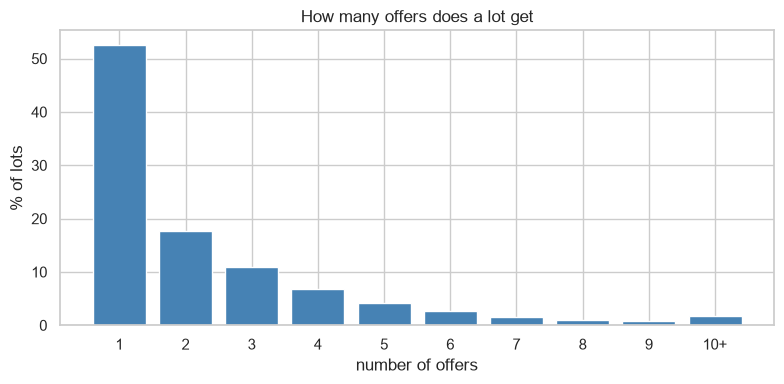

In [3]:
dist = lots["n_offers"].clip(upper=10).value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dist.index.astype(int).astype(str).str.replace("10", "10+"), dist.values * 100, color="steelblue")
ax.set(xlabel="number of offers", ylabel="% of lots", title="How many offers does a lot get")
plt.tight_layout()
plt.savefig("../images/offers_distribution.png", dpi=120)

In [4]:
print(f"single offer: {lots['single_offer'].mean():.1%}")
print(f"median offers: {lots['n_offers'].median():.0f}, mean: {lots['n_offers'].mean():.2f}")

single offer: 52.6%
median offers: 1, mean: 2.45


More than half of all lots get only one offer. The mean is pulled up by a few lots with dozens of offers.

## By type of contract and procedure

In [5]:
q('''
SELECT contract_nature, count(*) AS lots, round(avg(single_offer::int), 3) AS single_offer_share,
       round(avg(n_offers), 2) AS avg_offers
FROM fact_lot
WHERE n_offers >= 1
GROUP BY 1
ORDER BY 3 DESC
''')

,contract_nature,lots,single_offer_share,avg_offers
0,supplies,126764,0.58,2.15
1,services,49787,0.43,2.96
2,works,4477,0.11,5.16


In [6]:
q('''
SELECT procedure_type, count(*) AS lots, round(avg(single_offer::int), 3) AS single_offer_share
FROM fact_lot
WHERE n_offers >= 1
GROUP BY 1
HAVING count(*) > 500
ORDER BY 2 DESC
''')

,procedure_type,lots,single_offer_share
0,open,170408,0.51
1,neg-wo-call,7006,0.97
2,restricted,1828,0.57
3,oth-single,1291,0.83


Negotiated procedure without call (`neg-wo-call`) is basically direct award, so 97% single offer is
expected. But even in open tenders, where anyone can apply, half of the lots get one offer.
Works (construction) have the most competition.

## By category

In [7]:
by_cat = (
    lots.groupby("division_name_en")
    .agg(lots=("lot_key", "count"), single_offer_share=("single_offer", "mean"))
    .query("lots >= 1000")
    .sort_values("single_offer_share", ascending=False)
)
by_cat.index = by_cat.index.str.slice(0, 50)
by_cat

,lots,single_offer_share
division_name_en,,
"Laboratory, optical and precision equipments (excl",3997,0.68
"Medical equipments, pharmaceuticals and personal c",84340,0.67
"IT services: consulting, software development, Int",2774,0.66
Health and social work services,4055,0.65
Software package and information systems,3200,0.61
Repair and maintenance services,7039,0.59
"Radio, television, communication, telecommunicatio",1402,0.52
Transport equipment and auxiliary products to tran,5911,0.50
Chemical products,1399,0.47


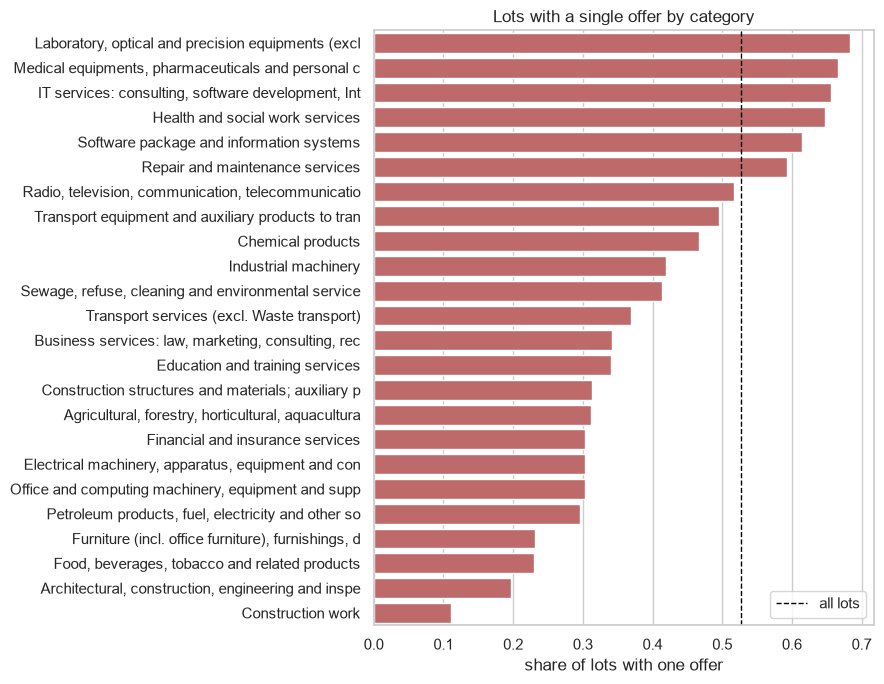

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
plot = by_cat.reset_index()
sns.barplot(data=plot, y="division_name_en", x="single_offer_share", color="indianred", ax=ax)
ax.axvline(lots["single_offer"].mean(), color="black", ls="--", lw=1, label="all lots")
ax.set(xlabel="share of lots with one offer", ylabel="", title="Lots with a single offer by category")
ax.legend()
plt.tight_layout()
plt.savefig("../images/single_offer_by_category.png", dpi=120)

## By buyer type and region

In [9]:
lots.groupby("buyer_type")["single_offer"].agg(["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
buyer_type,,
Public law body,137044,0.57
Other,3445,0.42
Local government,23432,0.42
Public company,6702,0.38
Central government,10405,0.34


In [10]:
(
    lots[~lots["voivodeship"].isin(["Unknown", "Whole country"])]
    .groupby("voivodeship")["single_offer"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

,count,mean
voivodeship,,
Kujawsko-pomorskie,7981,0.59
Pomorskie,12243,0.57
Śląskie,19766,0.56
Lubuskie,3079,0.56
Wielkopolskie,12834,0.55
Małopolskie,14339,0.55
Lubelskie,9184,0.54
Podkarpackie,8571,0.53
Dolnośląskie,12736,0.52


Regions differ less than categories (46% - 59%). The type of product matters much more than the
place. Public law bodies (mostly hospitals) have the highest share because of medical supplies.

## Is it getting better?

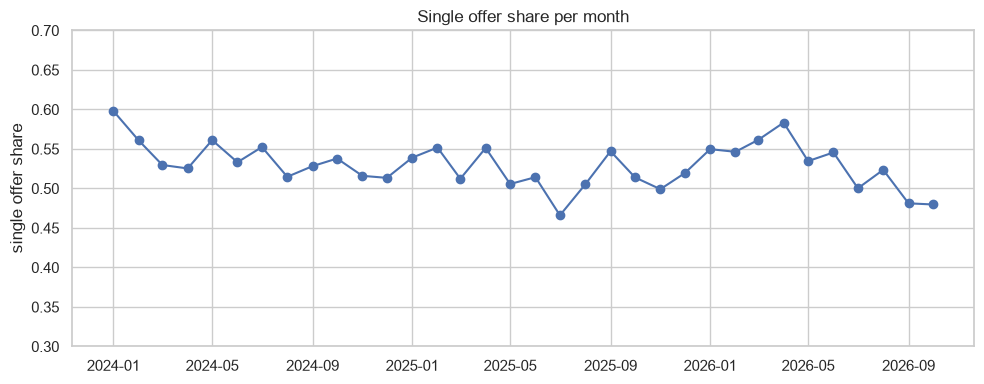

In [11]:
trend = q('''
SELECT publication_month AS month, avg(single_offer::int) AS single_offer_share, count(*) AS lots
FROM fact_lot
WHERE n_offers >= 1
GROUP BY 1
ORDER BY 1
''')
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trend["month"], trend["single_offer_share"], marker="o")
ax.set(ylim=(0.3, 0.7), ylabel="single offer share", title="Single offer share per month")
plt.tight_layout()

No clear trend - it stays around 50% for the whole period.

## Summary

- 53% of lots get only one offer, the median is 1 offer
- supplies (58%) are much worse than works (11%)
- laboratory equipment, medical supplies, IT services and software have the least competition
- region matters less than the category
- no improvement over 2024 - 2026